Лабараторная работа №1 по курсу: "Концепции машинного обучения".

В этой работе используется датасет Wine Quality, содержащий характеристики красного и белого вина. Цель исследования — изучить данные и определить, какие признаки могут быть полезны для предсказания качества вина.

Целевая переменная — `quality`, остальные характеристики используются как признаки для предсказания.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

In [2]:
url_red = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
url_white = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

red = pd.read_csv(url_red, sep=';')
white = pd.read_csv(url_white, sep=';')

print("Кол-во(данные, признаки)")
print("Красное вино: ", red.shape)
print("Белое вино: ", white.shape)

red["wine_type"] = "red"
white["wine_type"] = "white"

data = pd.concat([red, white], ignore_index=True)
display(data.head())

print("Общее кол-во: ", data.shape)

Кол-во(данные, признаки)
Красное вино:  (1599, 12)
Белое вино:  (4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


Общее кол-во:  (6497, 13)


In [3]:
print("Пропущенные значения по столбцам:")
display(data.isnull().sum().to_frame("Количество пропусков"))

print("Количество полных дубликатов:")
print(data.duplicated().sum())

print("Количество уникальных значений:")
display(data.nunique().to_frame("Количество уникальных значений"))

Пропущенные значения по столбцам:


,Количество пропусков
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Количество полных дубликатов:
1177
Количество уникальных значений:


,Количество уникальных значений
fixed acidity,106
volatile acidity,187
citric acid,89
residual sugar,316
chlorides,214
free sulfur dioxide,135
total sulfur dioxide,276
density,998
pH,108
sulphates,111


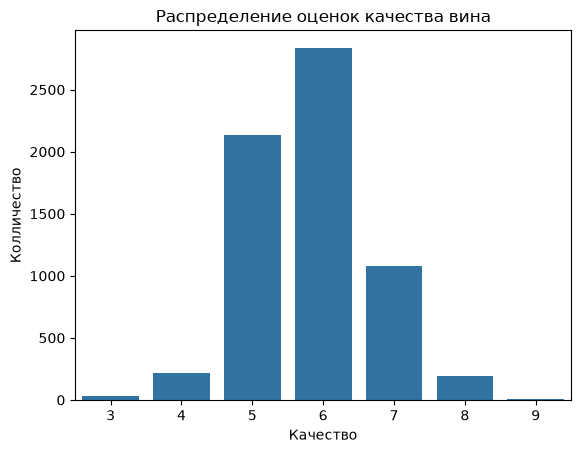

In [4]:
countplot = sns.countplot(data = data, x = "quality")
plt.title("Распределение оценок качества вина")
plt.xlabel("Качество")
plt.ylabel("Колличество")
plt.show()

По графику видно что большая часть вина получила оценки 5, 6 или 7. В свою очередь оценки 3 и 9 встречаются крайне редко, особенное 9.

В датасете присутствуют образцы двух типов вина. Сравним их по средней и медианной оценке качества, а также по разбросу оценок.

In [5]:
display(data.groupby("wine_type")["quality"].agg(["count", "mean", "median", "std"]).round(3))

,count,mean,median,std
wine_type,,,,
red,1599,5.636,6.0,0.808
white,4898,5.878,6.0,0.886


Посмотрим корреляцию пар признаков где одним эллементом пары всегда будет качество (quality) вина.

In [6]:
correlation = (data.corr(numeric_only=True)["quality"].drop("quality").sort_values())
print (correlation)

density                -0.305858
volatile acidity       -0.265699
chlorides              -0.200666
fixed acidity          -0.076743
total sulfur dioxide   -0.041385
residual sugar         -0.036980
pH                      0.019506
sulphates               0.038485
free sulfur dioxide     0.055463
citric acid             0.085532
alcohol                 0.444319
Name: quality, dtype: float64


Получившиеся значения говорят о следующем: близко к 1 - сильно положительная линейная связь, близко к 0 - слабая линейная связь или ее отсутствие, близко к -1 - сильно отрицательная линейная связь.

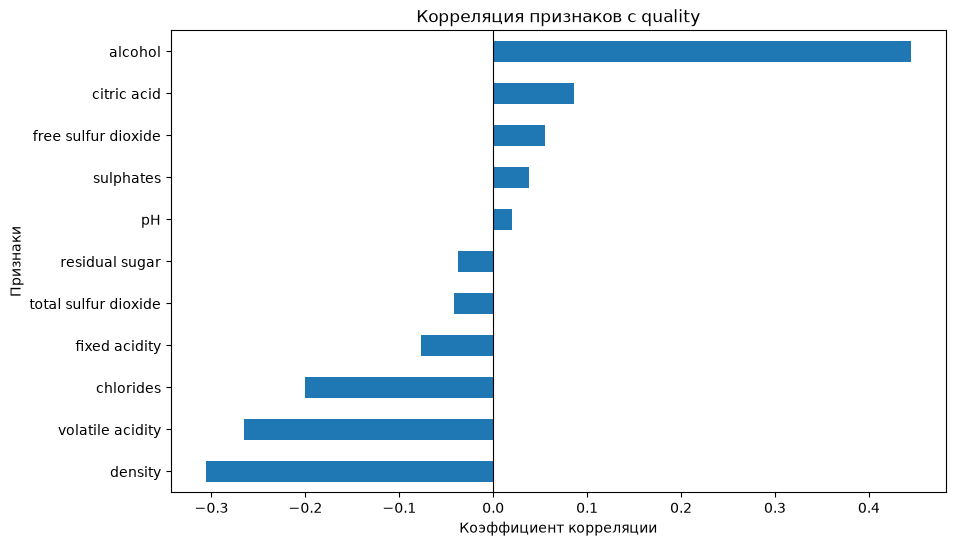

In [7]:
plt.figure(figsize=(10, 6))

correlation.plot(kind="barh")

plt.title("Корреляция признаков с quality")
plt.xlabel("Коэффициент корреляции")
plt.ylabel("Признаки")
plt.axvline(0, color="black", linewidth=0.8)

plt.show()

### Выводы по корреляционному анализу

Корреляционный анализ позволяет оценить линейную взаимосвязь между характеристиками вина и целевой переменной `quality`.

Признаки с положительной корреляцией связаны с тенденцией к увеличению оценки качества, а с отрицательной — с тенденцией к её уменьшению. При этом корреляция не означает причинно-следственную связь и не отражает все возможные зависимости между признаками и качеством вина.

Полученные результаты помогут при дальнейшем анализе моделей машинного обучения и сравнении важности признаков.

# Подготовка обучающей и тестовой выборок

Для обучения моделей необходимо разделить исходный датасет на обучающую и тестовую выборки.

Обучающая выборка будет использоваться для обучения моделей, а тестовая — для итоговой оценки качества их предсказаний.

В данной работе используем разделение **80% на обучение и 20% на тестирование**. Параметр `random_state=42` фиксирует случайное разбиение, что позволяет воспроизводить эксперимент.

Тестовую выборку не следует использовать при обучении и выборе параметров моделей, иначе оценка качества может оказаться необъективной.

In [8]:
X = data.drop(columns=["quality"])
X = pd.get_dummies(X, columns=["wine_type"], drop_first=True)

y = data["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Пропуски в X_train:", X_train.isnull().sum().sum())
print("Пропуски в X_test:", X_test.isnull().sum().sum())

print("Количество объектов для обучения:", len(X_train))
print("Количество объектов для тестирования:", len(X_test))

Пропуски в X_train: 0
Пропуски в X_test: 0
Количество объектов для обучения: 5197
Количество объектов для тестирования: 1300


# Baseline — базовая модель

В качестве базовой модели используем предсказание константой. Для каждого объекта тестовой выборки модель выдаёт одно и то же значение, равное среднему качеству вина в обучающей выборке.

Среднее выбрано потому, что оно минимизирует среднеквадратичную ошибку (RMSE) среди всех возможных постоянных предсказаний.

Baseline позволит оценить, насколько модели машинного обучения улучшают качество предсказаний по сравнению с простым прогнозом.

In [9]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

baseline_value = y_train.mean()

y_pred_baseline = np.full(len(y_test), baseline_value)

rmse_baseline = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
mae_baseline = mean_absolute_error(y_test, y_pred_baseline)

print("Константа baseline:", round(baseline_value, 3))
print("Baseline RMSE:", round(rmse_baseline, 3))
print("Baseline MAE:", round(mae_baseline, 3))

Константа baseline: 5.815
Baseline RMSE: 0.86
Baseline MAE: 0.669


# Линейная регрессия

Линейная регрессия строит зависимость целевой переменной `quality` от характеристик вина. В отличие от baseline, она учитывает значения признаков каждого объекта и может выдавать разные предсказания.

Оценим качество модели с помощью RMSE и MAE на тестовой выборке и сравним результаты с базовой моделью.

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

y_pred_lr = model_lr.predict(X_test)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr = mean_absolute_error(y_test, y_pred_lr)

print("Linear Regression RMSE:", round(rmse_lr, 3))
print("Linear Regression MAE:", round(mae_lr, 3))

Linear Regression RMSE: 0.736
Linear Regression MAE: 0.564


# Случайный лес

Алгоритм который строит много деревьев решений, каждое из которых предсказывает свою оценку качества вина. Алгоритм усредняет значение всех деревьев и выдает результат.

In [11]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

rf = RandomForestRegressor(random_state=42, n_jobs=-1)

param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 15, 25],
    "min_samples_leaf": [1, 2, 4]
}

grid_rf = GridSearchCV(
    rf,
    param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print("Лучшие параметры:", grid_rf.best_params_)
print("RMSE на кросс-валидации:", round(-grid_rf.best_score_, 3))

model_rf = grid_rf.best_estimator_

y_pred_rf = model_rf.predict(X_test)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)

print("Random Forest RMSE:", round(rmse_rf, 3))
print("Random Forest MAE:", round(mae_rf, 3))

Лучшие параметры: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 500}
RMSE на кросс-валидации: 0.616
Random Forest RMSE: 0.607
Random Forest MAE: 0.436


# Вывод по результатам Random Forest

В результате подбора гиперпараметров модели Random Forest с помощью GridSearchCV были получены следующие оптимальные параметры: `n_estimators=500`, `max_depth=None`, `min_samples_leaf=1`.

RMSE на кросс-валидации составил 0.616. При итоговой проверке на тестовой выборке RMSE составил 0.607, а MAE — 0.436.

Случайный лес показал лучший результат среди рассмотренных моделей. По сравнению с линейной регрессией RMSE уменьшился с 0.736 (на момент написания случ леса) до 0.607, а MAE — с 0.564 до 0.436.

Таким образом, Random Forest позволил достичь требуемого значения RMSE меньше 0.70.

# Градиентный бустинг
Это алгоритм, который также использует дерево решений, но с отличием. Он строит деревья последовательно так, что каждое следующее пытыется исправить ошибки предыдущего. 

In [12]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

gb = GradientBoostingRegressor(random_state=42)

param_grid_gb = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3],
    "min_samples_leaf": [2, 4]
}

grid_gb = GridSearchCV(
    gb,
    param_grid_gb,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid_gb.fit(X_train, y_train)

print("Лучшие параметры:", grid_gb.best_params_)
print("RMSE на кросс-валидации:", round(-grid_gb.best_score_, 3))

model_gb = grid_gb.best_estimator_
y_pred_gb = model_gb.predict(X_test)

rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
mae_gb = mean_absolute_error(y_test, y_pred_gb)

print("Gradient Boosting RMSE:", round(rmse_gb, 3))
print("Gradient Boosting MAE:", round(mae_gb, 3))

Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 4, 'n_estimators': 300}
RMSE на кросс-валидации: 0.668
Gradient Boosting RMSE: 0.662
Gradient Boosting MAE: 0.515


# Улучшение линейной регрессии

Так, как градиентный бустинг и случайный лес показали хорошие результы 0.662 и 0.607 соответсвенно, что меньше порога 0.7. Необходимо улучшить линейную регрессию.

# Диагностика данных

Чтобы понять, почему линейная регрессия даёт RMSE 0.736, посмотрим на сами признаки. Посчитаем для каждого признака максимальное отклонение от среднего в стандартных отклонениях (z-score) и асимметрию распределения (skew).

In [13]:
num_cols = [c for c in X_train.columns if c != "wine_type_white"]
X_train_f = X_train.astype(float)

z = (X_train_f[num_cols] - X_train_f[num_cols].mean()) / X_train_f[num_cols].std()

print("Максимальный |z-score| (больше ~5 — сильные выбросы):")
print(z.abs().max().sort_values(ascending=False).round(1))

print()
print("Асимметрия признаков (|skew| > 1 — длинный хвост):")
print(X_train_f[num_cols].skew().sort_values(key=abs, ascending=False).round(2))

Максимальный |z-score| (больше ~5 — сильные выбросы):
chlorides               15.9
density                 14.7
residual sugar          12.6
sulphates                9.9
volatile acidity         7.7
free sulfur dioxide      6.6
fixed acidity            6.5
citric acid              6.3
pH                       5.0
total sulfur dioxide     4.1
alcohol                  3.1
dtype: float64

Асимметрия признаков (|skew| > 1 — длинный хвост):
chlorides               5.68
sulphates               1.81
fixed acidity           1.73
volatile acidity        1.50
residual sugar          1.48
free sulfur dioxide     0.76
density                 0.62
alcohol                 0.57
citric acid             0.39
pH                      0.38
total sulfur dioxide   -0.05
dtype: float64


### Выводы по диагностике

У нескольких признаков есть значения, которые находятся очень далеко от среднего: `chlorides` (до 15.9 стандартных отклонений), `density` (14.7) и `residual sugar` (12.6). Кроме того, у `chlorides` очень длинный правый хвост (skew 5.68), а у `sulphates`, `fixed acidity`, `volatile acidity` и `residual sugar` асимметрия больше 1.

Линейная регрессия минимизирует сумму квадратов ошибок, поэтому небольшое число экстремальных объектов сильно влияет на все коэффициенты модели. Значит, улучшать нужно не саму модель, а данные, которые в неё подаются.

# Линейная регрессия с очисткой данных

Подготовим данные в два шага. Все параметры подготовки считаются только по обучающей выборке и затем применяются к тестовой.

1. **Обрезка выбросов.** Значения ниже `q`-го и выше `(1 - q)`-го процентиля заменяем на эти границы. Объекты при этом не удаляются, меняются только самые крайние значения.
2. **PowerTransformer (преобразование Йео — Джонсона).** Делает распределения признаков более симметричными, убирая длинные хвосты, и стандартизирует их.

Затем добавим полиномиальные признаки (квадраты и произведения признаков) и обучим линейную регрессию с Ridge-регуляризацией. Полином позволяет учесть нелинейные зависимости, а Ridge ограничивает коэффициенты, когда признаков становится много. Модель остаётся линейной по коэффициентам. Степень полинома (2 или 3) и `alpha` подберём с помощью `GridSearchCV`.

Долю обрезки `q` выберем по кросс-валидации на обучающей выборке, тестовую выборку при выборе не используем. Границы обрезки и параметры PowerTransformer считаются по всей обучающей выборке, а не отдельно внутри каждого фолда. Для подбора параметров это допустимое упрощение, на итоговую оценку на тесте оно не влияет.

In [14]:
from sklearn.preprocessing import PowerTransformer, PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

def prepare_data(q):
    X_train_p = X_train.astype(float)
    X_test_p = X_test.astype(float)

    lower = X_train_p[num_cols].quantile(q)
    upper = X_train_p[num_cols].quantile(1 - q)

    X_train_p[num_cols] = X_train_p[num_cols].clip(lower=lower, upper=upper, axis=1)
    X_test_p[num_cols] = X_test_p[num_cols].clip(lower=lower, upper=upper, axis=1)
    
    power = PowerTransformer()
    X_train_p[num_cols] = power.fit_transform(X_train_p[num_cols])
    X_test_p[num_cols] = power.transform(X_test_p[num_cols])

    return X_train_p, X_test_p

model_lr_clean = Pipeline([
    ("poly", PolynomialFeatures(include_bias=False)),
    ("scaler", StandardScaler()),
    ("regression", Ridge())
])

param_grid = {
    "poly__degree": [2, 3],
    "regression__alpha": [1, 10, 30, 100, 300, 1000]
}

cv_by_q = {}
for q in [0.002, 0.01, 0.025]:
    X_train_q, X_test_q = prepare_data(q)

    grid_q = GridSearchCV(
        model_lr_clean,
        param_grid,
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )
    grid_q.fit(X_train_q, y_train)

    cv_by_q[q] = -grid_q.best_score_
    print("q =", q, "| CV RMSE:", round(cv_by_q[q], 3), "|", grid_q.best_params_)

best_q = min(cv_by_q, key=cv_by_q.get)
print()
print("Лучшее q по CV:", best_q)

q = 0.002 | CV RMSE: 0.694 | {'poly__degree': 3, 'regression__alpha': 1000}
q = 0.01 | CV RMSE: 0.692 | {'poly__degree': 3, 'regression__alpha': 1000}
q = 0.025 | CV RMSE: 0.691 | {'poly__degree': 3, 'regression__alpha': 1000}

Лучшее q по CV: 0.025


Обучим модель с выбранным `q` и один раз оценим её на тестовой выборке.

In [15]:
X_train_clean, X_test_clean = prepare_data(best_q)

grid_lr_clean = GridSearchCV(
    model_lr_clean,
    param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid_lr_clean.fit(X_train_clean, y_train)

model_lr_clean = grid_lr_clean.best_estimator_
y_pred_lr_clean = model_lr_clean.predict(X_test_clean)

rmse_lr_clean = np.sqrt(mean_squared_error(y_test, y_pred_lr_clean))
mae_lr_clean = mean_absolute_error(y_test, y_pred_lr_clean)

print("Best parameters:", grid_lr_clean.best_params_)
print("CV RMSE:", round(-grid_lr_clean.best_score_, 3))
print("Linear Regression (очистка данных) RMSE:", round(rmse_lr_clean, 3))
print("Linear Regression (очистка данных) MAE:", round(mae_lr_clean, 3))

Best parameters: {'poly__degree': 3, 'regression__alpha': 1000}
CV RMSE: 0.691
Linear Regression (очистка данных) RMSE: 0.68
Linear Regression (очистка данных) MAE: 0.533


# Вывод по улучшению линейной регрессии

Обычная линейная регрессия показала RMSE 0.736. Диагностика показала, что у признаков есть выбросы и длинные хвосты распределений, из-за которых несколько объектов сильно влияют на коэффициенты модели.

После обрезки выбросов по процентилям (`q = 0.025`), преобразования признаков с помощью PowerTransformer и добавления полиномиальных признаков (степень 3) с Ridge-регуляризацией (`alpha = 1000`) RMSE на кросс-валидации составил **0.691**, а на тестовой выборке — **0.68**, MAE — **0.533**. Это меньше требуемого порога 0.7.

Таким образом, улучшение дали три шага вместе: очистка данных убрала влияние выбросов, полиномиальные признаки добавили гибкость (изгибы зависимостей и взаимодействия признаков), а Ridge не дал коэффициентам разрастись при таком большом числе признаков.

# Честное сравнение моделей

Ниже приведена таблица сравнения реализованных моделей по RMSE и MAE.

In [16]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

results = {
    "Baseline": [rmse_baseline, mae_baseline],
    "Linear Regression": [rmse_lr, mae_lr],
    "Random Forest": [rmse_rf, mae_rf],
    "Gradient Boosting": [rmse_gb, mae_gb],
    "Linear Regression (очистка данных)": [rmse_lr_clean, mae_lr_clean]
}

results_table = pd.DataFrame(results, index=["RMSE", "MAE"]).T
results_table = results_table.sort_values("RMSE")
display(results_table.round(3))

,RMSE,MAE
Random Forest,0.607,0.436
Gradient Boosting,0.662,0.515
Linear Regression (очистка данных),0.680,0.533
Linear Regression,0.736,0.564
Baseline,0.860,0.669


### Выводы по сравнению моделей
Все модели проверяются на одной и той же тестовой выборке, поэтому их результаты можно сравнивать между собой. Baseline показывает качество простого предсказания средним значением и служит точкой отсчёта.

Модель считается лучше baseline, если её RMSE меньше. Случайный лес и градиентный бустинг могут находить нелинейные зависимости между признаками, поэтому на таких данных они часто работают лучше обычной линейной регрессии. Линейная регрессия строит более простую зависимость и может не учитывать сложные взаимодействия признаков.

RMSE показывает типичный размер ошибки с усиленным влиянием крупных ошибок. MAE показывает среднюю абсолютную величину ошибки. RMSE сильнее реагирует на большие ошибки, потому что перед усреднением ошибки возводятся в квадрат. Поэтому RMSE и MAE одной модели могут различаться: если есть несколько особенно больших ошибок, RMSE будет заметно выше MAE.

# Feature importance

Посмотрим, какие признаки оказались наиболее важными для случайного леса, градиентного бустинга и линейной регрессии. Для деревьев важность признака (`feature_importances_`) показывает, насколько сильно признак помогает делить данные и уменьшать ошибку. Для линейной регрессии аналогом служат коэффициенты (после приведения признаков к одному масштабу).

Начнём со случайного леса.

,Важность
alcohol,0.2558
volatile acidity,0.1282
free sulfur dioxide,0.0893
sulphates,0.0785
total sulfur dioxide,0.0715
residual sugar,0.0702
pH,0.0696
chlorides,0.0631
citric acid,0.0588
density,0.0583


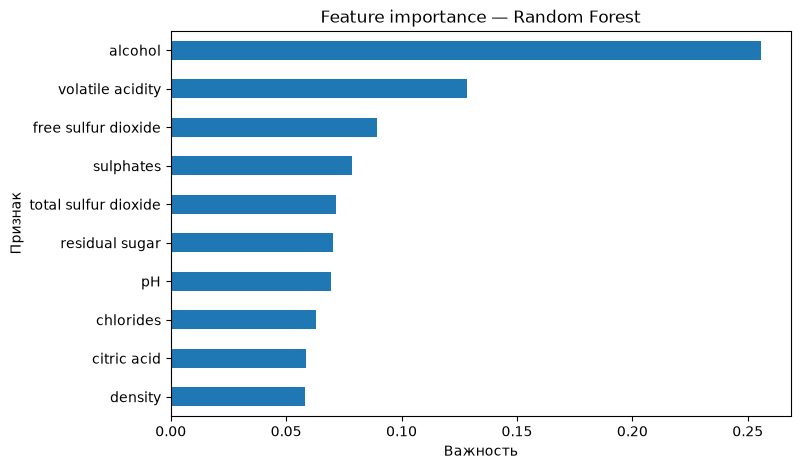

In [17]:
importance_rf = pd.Series(model_rf.feature_importances_, index=X_train.columns)
importance_rf = importance_rf.sort_values(ascending=False)

display(importance_rf.to_frame("Важность").head(10).round(4))

plt.figure(figsize=(8, 5))
importance_rf.head(10).sort_values().plot(kind="barh")
plt.title("Feature importance — Random Forest")
plt.xlabel("Важность")
plt.ylabel("Признак")
plt.show()

Теперь то же самое для градиентного бустинга.

In [ ]:
importance_gb = pd.Series(model_gb.feature_importances_, index=X_train.columns)
importance_gb = importance_gb.sort_values(ascending=False)

display(importance_gb.to_frame("Важность").head(10).round(4))

plt.figure(figsize=(8, 5))
importance_gb.head(10).sort_values().plot(kind="barh")
plt.title("Feature importance — Gradient Boosting")
plt.xlabel("Важность")
plt.ylabel("Признак")
plt.show()

Для линейной регрессии посмотрим на коэффициенты. Сравнивать их напрямую нельзя, пока признаки измерены в разных масштабах: например, `density` меняется в пределах сотых долей, а `total sulfur dioxide` — в сотнях, поэтому их коэффициенты несопоставимы. Приведём признаки к одному масштабу с помощью `StandardScaler`. Предсказания модели от этого не изменятся (RMSE останется 0.736), изменится только смысл коэффициентов: каждый покажет, на сколько баллов меняется оценка при росте признака на одно стандартное отклонение.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

model_lr_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])
model_lr_scaled.fit(X_train, y_train)

rmse_check = np.sqrt(mean_squared_error(y_test, model_lr_scaled.predict(X_test)))
print("RMSE линейной регрессии с масштабированием:", round(rmse_check, 3))

coef_lr = pd.Series(
    model_lr_scaled.named_steps["regression"].coef_,
    index=X_train.columns
).sort_values()

print()
print("Коэффициенты (изменение quality при росте признака на 1 стандартное отклонение):")
print(coef_lr.round(3))

plt.figure(figsize=(10, 6))
coef_lr.plot(kind="barh")
plt.title("Коэффициенты линейной регрессии (признаки масштабированы)")
plt.xlabel("Изменение quality при росте признака на 1 σ")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

Теперь сведём важность признаков у всех трёх моделей в одну таблицу и на один график. Чтобы значения можно было сопоставить, для линейной регрессии возьмём модуль коэффициента и поделим на сумму модулей. Тогда у всех трёх моделей важность записана как доля, и в сумме по признакам получается 1.

In [ ]:
importance_all = pd.DataFrame({
    "Linear Regression": coef_lr.abs() / coef_lr.abs().sum(),
    "Random Forest": importance_rf,
    "Gradient Boosting": importance_gb,
})

importance_all = importance_all.sort_values("Random Forest", ascending=True)

importance_all.plot(kind="barh", figsize=(10, 8))
plt.title("Важность признаков (доля от суммы)")
plt.xlabel("Важность")
plt.show()

display(importance_all.sort_values("Random Forest", ascending=False).round(3))

print("Топ-3 признака по каждой модели:")
for model_name in importance_all.columns:
    top3 = importance_all[model_name].sort_values(ascending=False).head(3)
    print(model_name, "->", ", ".join(top3.index))

### Выводы по важности признаков

**Наиболее важные признаки.**

- Random Forest: `alcohol` (0.256), `volatile acidity` (0.128), `free sulfur dioxide` (0.089).
- Gradient Boosting: <впиши 3 верхних признака>.
- Linear Regression: <впиши 3 признака с наибольшими по модулю коэффициентами>.

**Сравнение моделей.** <впиши: совпали ли верхние признаки у трёх моделей и чем списки различаются>. Random Forest и Gradient Boosting устроены похоже (оба на деревьях), поэтому их списки обычно близки. Деревья не показывают направление влияния, а у линейной регрессии знак коэффициента показывает, повышает признак оценку или понижает.

**Сравнение с первичным анализом.** В корреляционном анализе самыми сильными были `alcohol` (0.44), `density` (−0.31), `volatile acidity` (−0.27) и `chlorides` (−0.20). Два главных признака случайного леса (`alcohol` и `volatile acidity`) входят в этот список. При этом `density`, у которого вторая по силе корреляция, у случайного леса оказался только на 10-м месте (0.058), а `chlorides` — на 8-м (0.063). Возможное объяснение: `density` сильно связан с `alcohol` и `residual sugar`, поэтому когда `alcohol` уже учтён, `density` добавляет мало новой информации. <впиши: что показали Gradient Boosting и линейная регрессия>.

**Можно ли по feature importance утверждать, что изменение признака является причиной изменения качества вина?** Нет. Важность признака показывает только, насколько сильно модель использует его для предсказания, то есть отражает статистическую связь, а не причину. Причины:

- Данные наблюдательные: мы не меняли признак при прочих равных условиях и не смотрели, как изменится оценка.
- Признаки связаны между собой (например, `alcohol` и `density`). Важность одного может отражать влияние другого, а между связанными признаками важность делится, и распределение зависит от модели.
- В данных нет скрытых факторов (сорт винограда, производитель, год урожая), которые могут влиять и на признак, и на оценку.
- Оценка `quality` — субъективное мнение экспертов, а не измеренная величина.

Например, высокая важность `alcohol` не означает, что добавление спирта повысит оценку вина: возможно, более крепкое вино получается из более спелого винограда, и экспертам нравится именно это.

# Анализ ошибок

Для анализа выберем лучшую из обученных моделей по RMSE на тестовой выборке. Baseline не рассматриваем, так как это простое константное предсказание.

In [18]:
model_results = {
    "Linear Regression": (rmse_lr, model_lr, y_pred_lr),
    "Random Forest": (rmse_rf, model_rf, y_pred_rf),
    "Gradient Boosting": (rmse_gb, model_gb, y_pred_gb),
    "Linear Regression (очистка данных)": (rmse_lr_clean, model_lr_clean, y_pred_lr_clean)
}

best_model_name = min(model_results, key=lambda name: model_results[name][0])
best_rmse, best_model, best_predictions = model_results[best_model_name]

print("Лучшая модель:", best_model_name)
print("RMSE:", round(best_rmse, 3))

Лучшая модель: Random Forest
RMSE: 0.607


Первые строки с предсказаниями:


,Истинное quality,Предсказанное quality,Ошибка,Абсолютная ошибка
3103,8,6.356,1.644,1.644
1419,5,5.190,-0.190,0.190
4761,7,6.958,0.042,0.042
4690,6,5.372,0.628,0.628
4032,6,5.018,0.982,0.982


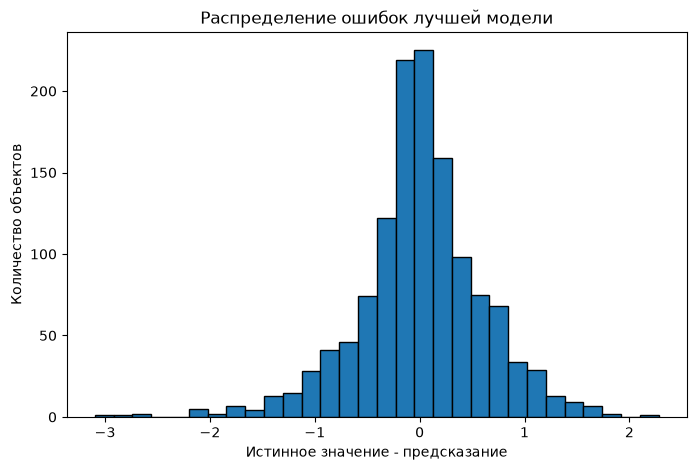

In [19]:
errors = y_test.to_numpy() - best_predictions
error_data = pd.DataFrame({
    "Истинное quality": y_test.to_numpy(),
    "Предсказанное quality": best_predictions,
    "Ошибка": errors,
    "Абсолютная ошибка": np.abs(errors)
}, index=y_test.index)

print("Первые строки с предсказаниями:")
display(error_data.head())

plt.figure(figsize=(8, 5))
plt.hist(errors, bins=30, edgecolor="black")
plt.title("Распределение ошибок лучшей модели")
plt.xlabel("Истинное значение - предсказание")
plt.ylabel("Количество объектов")
plt.show()

In [20]:
worst_errors = error_data.sort_values("Абсолютная ошибка", ascending=False).head(10)
display(worst_errors.round(3))

,Истинное quality,Предсказанное quality,Ошибка,Абсолютная ошибка
2339,3,6.096,-3.096,3.096
6344,3,5.738,-2.738,2.738
3649,3,5.692,-2.692,2.692
3016,3,5.670,-2.670,2.670
3204,9,6.722,2.278,2.278
3715,4,6.166,-2.166,2.166
1374,3,5.124,-2.124,2.124
4656,5,7.118,-2.118,2.118
3758,4,6.092,-2.092,2.092
4417,4,6.034,-2.034,2.034


,Количество,MAE,RMSE
Истинное quality,,,
3,6,2.528,2.562
4,43,1.192,1.272
5,402,0.387,0.540
6,597,0.324,0.422
7,215,0.511,0.642
8,36,1.097,1.216
9,1,2.278,2.278


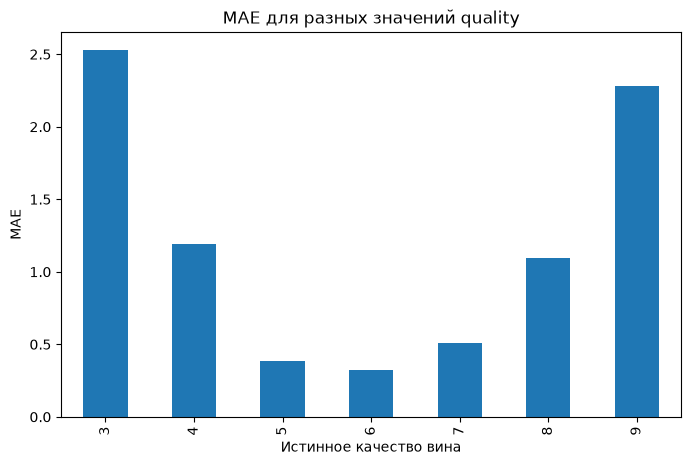

In [21]:
quality_errors = error_data.groupby("Истинное quality").agg(
    Количество=("Ошибка", "count"),
    MAE=("Абсолютная ошибка", "mean"),
    RMSE=("Ошибка", lambda x: np.sqrt(np.mean(x ** 2)))
)

display(quality_errors.round(3))

plt.figure(figsize=(8, 5))
quality_errors["MAE"].plot(kind="bar")
plt.title("MAE для разных значений quality")
plt.xlabel("Истинное качество вина")
plt.ylabel("MAE")
plt.show()

### Выводы по анализу ошибок

По распределению ошибок можно оценить, в какую сторону модель чаще ошибается и насколько сильно отличаются предсказания от истинных значений. В таблице выше показаны объекты с наибольшими абсолютными ошибками.

Сравнение ошибок по значениям quality позволяет проверить, одинаково ли хорошо модель работает для разных оценок. Редкие значения качества представлены меньшим количеством объектов, поэтому модели сложнее находить для них закономерности. Кроме того, соседние оценки качества могут иметь похожие характеристики, из-за чего модель путает их.

Большие ошибки могут быть связаны с необычным сочетанием характеристик конкретного вина или с тем, что в данных недостаточно похожих примеров для обучения.

# Общий вывод

В ходе лабораторной работы был изучен датасет Wine Quality, проведён первичный анализ признаков и построены модели для предсказания качества вина.

В качестве baseline использовалось предсказание среднего значения целевой переменной. Затем были обучены линейная регрессия, случайный лес и градиентный бустинг. Модели сравнивались по RMSE и MAE на одной тестовой выборке.

Также была рассмотрена важность признаков для моделей на основе деревьев и проведён анализ ошибок лучшей модели. По результатам эксперимента можно сделать вывод, что использование характеристик вина позволяет получать более точные предсказания, чем простое предсказание константой.